In [1]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

DATA = Path("../data")
COLS = ["label", "id", "date", "query", "user", "tweet"]

In [2]:
train = pd.read_csv(DATA / "training.1600000.processed.noemoticon.csv",
                    encoding="latin-1", header=None, names=COLS)
print(train.shape)

(1600000, 6)


In [3]:
print(train["label"].value_counts())
train["label"] = train["label"].map({0: 0, 4: 1})
train["label"].value_counts()

label
0    800000
4    800000
Name: count, dtype: int64


label
0    800000
1    800000
Name: count, dtype: int64

In [4]:
tweetCount = train["tweet"].str.split().str.len()
train["tweet count"] = tweetCount
train.head()

,label,id,date,query,user,tweet,tweet count
0,0,1467810369,Mon Apr 06 22:19:45 PDT 2009,NO_QUERY,_TheSpecialOne_,"@switchfoot http://twitpic.com/2y1zl - Awww, t...",19
1,0,1467810672,Mon Apr 06 22:19:49 PDT 2009,NO_QUERY,scotthamilton,is upset that he can't update his Facebook by ...,21
2,0,1467810917,Mon Apr 06 22:19:53 PDT 2009,NO_QUERY,mattycus,@Kenichan I dived many times for the ball. Man...,18
3,0,1467811184,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,ElleCTF,my whole body feels itchy and like its on fire,10
4,0,1467811193,Mon Apr 06 22:19:57 PDT 2009,NO_QUERY,Karoli,"@nationwideclass no, it's not behaving at all....",21


count   1600000.00
mean         13.18
std           6.96
min           1.00
25%           7.00
50%          12.00
75%          19.00
max          64.00
Name: tweet, dtype: float64
95th percentile: 25.0
99th percentile: 28.0


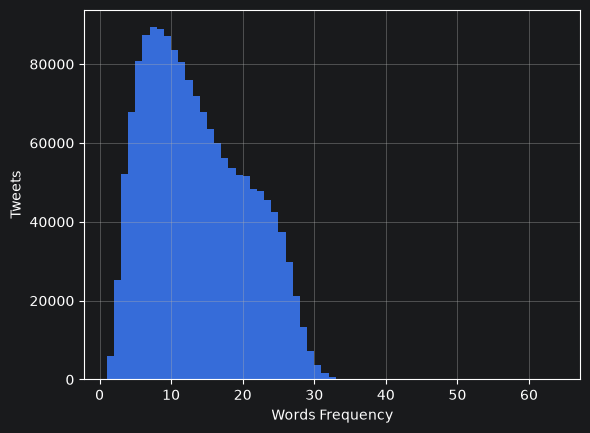

In [5]:
pd.set_option("display.float_format", "{:.2f}".format)
print(tweetCount.describe())
print(f"95th percentile: {tweetCount.quantile(0.95)}")
print(f"99th percentile: {tweetCount.quantile(0.99)}")
tweetCount.hist(bins="auto")
plt.ylabel("Tweets")
plt.xlabel("Words Frequency")
plt.show()

In [6]:
negative_tweets = train["label"] == 0
is_negative_tweets = train[negative_tweets].sample(n=10, random_state=42)
positive_tweets = train["label"] == 1
is_positive_tweets = train[positive_tweets].sample(n=10, random_state=42)
print(is_negative_tweets["tweet"])
print(is_positive_tweets["tweet"])

212188    @xnausikaax oh no! where did u order from? tha...
299036    A great hard training weekend is over.  a coup...
475978    Right, off to work  Only 5 hours to go until I...
588988                      I am craving for japanese food 
138859    Jean Michel Jarre concert tomorrow  gotta work...
764498        @xPowxBangxBoomx dammiitt!! i wish i had MTV 
337706    @Rohan_01 You know..it's really sad that u kno...
257163                              @FaketragedyCom i know 
632647         @JudahGabriel i wish i had that much to say 
517320    ow, i can't move my neck or my back   hurts to...
Name: tweet, dtype: str
1012188    Is lookin 4ward to a long weekend  really dont...
1099036    #myweakness  Is music and i live to meet the p...
1275978             figured out the Internet on my new iPod 
1388988    @hillsongunited can't wait to worship with you...
938859     @sillybeggar Congrats James !! I'm sure the bo...
1564498    @DebbyBruck beautiful! when children smile the...
1137706   

In [7]:
tweet_content = train["tweet"]
tweet_duplicate = tweet_content.duplicated().sum()
tweet_URL = tweet_content.str.contains("http").sum()/len(tweet_content)
tweet_hashtag = tweet_content.str.contains("#").sum()/len(tweet_content)
tweet_html = tweet_content.str.contains("&amp;").sum()/len(tweet_content) + tweet_content.str.contains("&quot;").sum()/len(tweet_content)
print(tweet_duplicate)
print(tweet_URL)
print(tweet_hashtag)
print(tweet_html)


18534
0.043864375
0.0230075
0.0481675


In [8]:
sample_tweets = train.sample(n=50, random_state=42)
for i, (label, tweet) in enumerate(zip(sample_tweets["label"], sample_tweets["tweet"])):
    print(f"{i:2d} [{label}] {tweet}")

 0 [0] @chrishasboobs AHHH I HOPE YOUR OK!!! 
 1 [0] @misstoriblack cool , i have no tweet apps  for my razr 2
 2 [0] @TiannaChaos i know  just family drama. its lame.hey next time u hang out with kim n u guys like have a sleepover or whatever, ill call u
 3 [0] School email won't open  and I have geography stuff on there to revise! *Stupid School* :'(
 4 [0] upper airways problem 
 5 [0] Going to miss Pastor's sermon on Faith... 
 6 [1] on lunch....dj should come eat with me 
 7 [0] @piginthepoke oh why are you feeling like that? 
 8 [0] gahh noo!peyton needs to live!this is horrible 
 9 [1] @mrstessyman thank you glad you like it! There is a product review bit on the site  Enjoy knitting it!
10 [1] @PerezHilton Zach makes me pee sitting down! And I'm a grown gay man! 
11 [1] to sum up my day in one word ......... kackered! 
12 [1] @k9wkj Great minds think alike 
13 [0] Is Poorly and in bed! 
14 [1] @LilPecan Oh, that's really great  Here we have a small blizzard and also cold wind bl

### Dataset size and class balance
- 1,600,000 tweets from Sentiment140 (Kaggle copy).
- Perfectly balanced: 800,000 negative (label 0) and 800,000 positive (label 1).
- Baseline accuracy is 50%, since guessing 1 class every time will give 50% accuracy.

### Tweet length (words)
- Median: 12 words, mean: 13.2, standard deviation: 7.0.
- 25% of tweets have 7 words or fewer, 75% have 19 or fewer.
- Shortest: 1 word. Longest: 64 words.
- 95% of tweets have 25 words or fewer; 99% have 28 or fewer.
- Long tweets are rare outliers: the gap between the 75% point (19) and the maximum (64) is large.

### Duplicates, URLs, mentions, and other oddities
- Exact duplicate tweets: 18,534.
- Tweets containing URLs: 4.38%. Tweets containing @mentions: 2.30%.
- HTML leftovers appear in the text, e.g. `&amp;` for "&" and `&quot;` for a quotation mark: 4.81%
- Some tweets have syntax errors, e.g. tweet No. 48: "Brï¿½ndby".

### Examine the tweets
I read a random sample of 50 tweets (random_state=42) and judged each label:
- Correct: 39 of 50 (78%)
- Incorrect: about 5 of 50 (10%) (tweet No. 11,14,29,42,48)
- Unclear or neutral: 6 of 50 (24%) (tweet No. 6,15,22,33,43,46)

Examples of likely incorrect labels:
- #11, labeled positive: "to sum up my day in one word ......... kackered!".
- #48, labeled positive: "FCK-Brï¿½ndby 4-0! ..."

Examples of unclear tweets with no real sentiment:
- #6, labeled positive: "on lunch....dj should come eat with me"
- #43, labeled positive: "eating cha with eric"

### What this means for the next steps
**Preprocessing**
- Replace URLs and @mentions with placeholder tokens (e.g. "URL", "USER"): they rarely carry sentiment and add many rare words.
- Convert HTML leftovers back to normal characters (`&amp;` → "&").
- Keep punctuation like "!!!" and "...", and stretched words: they carry emotion.
- Decide how to handle exact duplicates so the same tweet can't appear in both training and test data.

**Maximum length for the transformer**
- 99% of tweets have 28 words or fewer. Tweets become more tokens than words (mentions, slang, and stretched words split into pieces), so 64 tokens is a reasonable starting limit.

**Evaluation**
- The test set comes from the same noisy data. With about 10% of labels wrong and 12% without real sentiment in my sample, even a perfect model would be marked "wrong" on some tweets, so accuracy above roughly 85–90% is unlikely for any model.